# Modelo 3 · Viviendas afectadas y costos · Registro del entrenamiento

**UTSmart IA Challenge 2027 – Categoría Básica**

Este modelo estima cuántas viviendas se averiarían o destruirían en un municipio según la intensidad con que le llegue un sismo,
y traduce ese daño a un rango de costo. Se apoya en lo que realmente ocurrió en sismos colombianos de 2019 a 2025.

| Fuente | Archivo original (`entrenamiento/data/raw/danos_y_costos`) | Uso |
| :--- | :--- | :--- |
| UNGRD, emergencias (datos.gov.co) | `ungrd_emergencias/` (2019, 2020, 2023-2024 y 2025) | Daños reportados por municipio y valores de la ayuda |
| DANE, proyecciones de viviendas 2018-2042 | `dane_viviendas_y_hogares/` | Cuántas viviendas había en cada municipio |
| DANE, DIVIPOLA | `dane_divipola/` | Código y coordenadas de cada municipio |
| USGS, catálogo ANSS | `usgs_catalogo_colombia/` | Qué sismo fue: magnitud, profundidad y epicentro |

> **Estado: entrenado y validado. Es un modelo de primera aproximación: léase la sección 7.**

In [1]:
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

warnings.filterwarnings("ignore")
MODELO = Path.cwd().parent
sys.path.insert(0, str(MODELO / "src"))
sys.path.insert(0, str(MODELO.parent / "comun" / "src"))
pd.set_option("display.max_columns", 40, "display.width", 200, "display.float_format", lambda v: f"{v:,.3f}")
AZUL, NARANJA = "#2a78d6", "#eb6834"
COLOR_NIVEL = {"Bajo": "#1baf1b", "Medio": "#f5b21a", "Alto": "#d83a3a"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e1e0d9", "axes.axisbelow": True, "font.size": 10})

import preparar_danos as danos
import simulador as sim
relativa = lambda ruta: Path(ruta).relative_to(danos.RAW_DIR.parents[1]).as_posix()
print("ARCHIVOS ORIGINALES")
for ruta in sorted(danos.DANOS_DIR.rglob("*")):
    if ruta.is_file():
        print(f"   {relativa(ruta):95s} {ruta.stat().st_size / 1e6:7.2f} MB")

ARCHIVOS ORIGINALES
   data/raw/danos_y_costos/dane_divipola/divipola_municipios.csv                                      0.07 MB
   data/raw/danos_y_costos/dane_viviendas_y_hogares/proyecciones_hogares_dptal_mpal_2018_2042.xlsx    0.67 MB
   data/raw/danos_y_costos/dane_viviendas_y_hogares/proyecciones_viviendas_dptal_mpal_2018_2042.xlsx    1.28 MB
   data/raw/danos_y_costos/gobernacion_santander/reporte_eventos_desastres_santander.csv              0.74 MB
   data/raw/danos_y_costos/ungrd_emergencias/emergencias_ungrd_2019.csv                               1.02 MB
   data/raw/danos_y_costos/ungrd_emergencias/emergencias_ungrd_2020.csv                               3.30 MB
   data/raw/danos_y_costos/ungrd_emergencias/emergencias_ungrd_2023_2024.csv                         15.77 MB
   data/raw/danos_y_costos/ungrd_emergencias/emergencias_ungrd_2025.csv                              11.56 MB
   data/raw/danos_y_costos/usgs_catalogo_colombia/sismos_usgs_colombia_2019_2025.geojson          

## 1. Las emergencias de la UNGRD, tal como llegan

Cada archivo trae columnas distintas para lo mismo, y todo llega como texto.

In [2]:
for ruta in danos.ARCHIVOS_UNGRD:
    crudo = pd.read_csv(ruta, dtype=str)
    de_dano = [c for c in crudo.columns if "VIV" in c.upper() or "FALLEC" in c.upper() or "MUERT" in c.upper()]
    de_valor = [c for c in crudo.columns if "TOTAL" in c.upper() or "RECURSOS" in c.upper()]
    print(f"{ruta.name}: {len(crudo):,} filas, {crudo.shape[1]} columnas")
    print("   daño: ", de_dano)
    print("   valor:", de_valor)
display(crudo.iloc[:3, :14])

emergencias_ungrd_2019.csv: 4,437 filas, 73 columnas
   daño:  ['FALLECIDOS', 'VIVIENDAS DESTRUIDAS', 'VIVIENDAS AVERIADAS']
   valor: ['RECURSOS EJECUTADOS', 'VALOR TOTAL ASISTENCIA NO ALIMENTARIA', 'VALOR TOTAL  APOYO DEL FNGRD']
emergencias_ungrd_2020.csv: 3,811 filas, 74 columnas
   daño:  ['FALLECIDOS', 'VIVIENDAS DESTRUIDAS', 'VIVIENDAS AVERIADAS']
   valor: ['RECURSOS EJECUTADOS', 'VALOR TOTAL ASISTENCIA NO ALIMENTARIA', 'VALOR APOYO TOTAL DEL FNGRD']


emergencias_ungrd_2023_2024.csv: 16,036 filas, 69 columnas
   daño:  ['FALLECIDOS', 'VIVIENDAS DESTRUIDAS', 'VIVIENDAS AVERIADAS']
   valor: ['VALOR TOTAL  APOYO', 'VALOR TOTAL SUBSIDIOS DE ARRIENDO', 'APOYO TOTAL DEL FNGRD']
emergencias_ungrd_2025.csv: 13,012 filas, 61 columnas
   daño:  ['FALLECIDOS', 'VIVIENDAS DESTRUIDAS', 'VIVIVIENDAS AVERIADAS']
   valor: ['VALOR - APOYO TOTAL DEL FNGRD']


,FECHA,DEPARTAMENTO,MUNICIPIO,EVENTO,CODIFICACIÓN SEGUN DIVIPOLA,COORDENADAS,FALLECIDOS,HERIDOS,DESAPARECIDOS,PERSONAS,FAMILIAS,VIVIENDAS DESTRUIDAS,VIVIVIENDAS AVERIADAS,VIAS
0,01/01/2025 12:00:00 AM,CESAR,BECERRIL,AVENIDA TORRENCIAL,20045,0,0,0,0,32,8,0,0,0
1,01/01/2025 12:00:00 AM,CESAR,CHIRIGUANA,INCENDIO ESTRUCTURAL,20046,0,0,0,0,4,1,0,1,0
2,01/01/2025 12:00:00 AM,CESAR,EL PASO,INCENDIO FORESTAL,20047,0,0,0,0,0,0,0,0,0


## 2. Limpieza y unión

Se llevan los cuatro archivos a las mismas columnas, los conteos pasan de texto a número (lo que no es un número cuenta como cero) y los valores en pesos se limpian de símbolos y separadores.

   -> emergencias_ungrd_2019.csv: 4,437 emergencias
   -> emergencias_ungrd_2020.csv: 3,811 emergencias


   -> emergencias_ungrd_2023_2024.csv: 16,036 emergencias
   -> emergencias_ungrd_2025.csv: 13,012 emergencias


   -> Total: 37,295 emergencias (1 sin fecha, descartadas)



,archivo,fecha,departamento,municipio,evento,divipola,fallecidos,heridos,personas,familias,viviendas_destruidas,viviendas_averiadas,apoyo_total_cop
0,emergencias_ungrd_2019.csv,2019-01-01,ANTIOQUIA,SAN JERONIMO,INCENDIO ESTRUCTURAL,5656,0,0,5,1,1,0,0.000
1,emergencias_ungrd_2019.csv,2019-01-01,RISARALDA,MARSELLA,INMERSION,66440,1,0,1,0,0,0,0.000
2,emergencias_ungrd_2019.csv,2019-01-01,ANTIOQUIA,ANZA,INCENDIO DE COBERTURA VEGETAL,5044,0,0,0,0,0,0,0.000
3,emergencias_ungrd_2019.csv,2019-01-01,ANTIOQUIA,MONTEBELLO,INCENDIO DE COBERTURA VEGETAL,5467,0,0,0,0,0,0,0.000
4,emergencias_ungrd_2019.csv,2019-01-01,ANTIOQUIA,CAUCASIA,INCENDIO ESTRUCTURAL,5154,0,1,1,1,1,0,0.000


Emergencias por año: {2019: 4436, 2020: 3811, 2023: 5475, 2024: 10561, 2025: 13012}


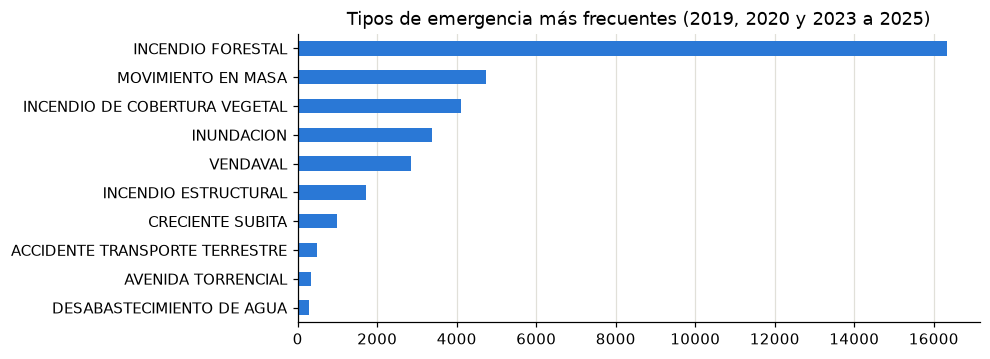

Emergencias por sismo: 166 de 37,295 (puesto 15 entre 55 tipos)


In [3]:
emergencias = danos.unir_emergencias()
print()
display(emergencias.head(5))
print("Emergencias por año:", emergencias.groupby(emergencias["fecha"].dt.year).size().to_dict())
tipos = emergencias["evento"].value_counts()
fig, eje = plt.subplots(figsize=(8, 3.4))
tipos.head(10)[::-1].plot.barh(ax=eje, color=[NARANJA if "SISMO" in t else AZUL for t in tipos.head(10)[::-1].index])
eje.set(title="Tipos de emergencia más frecuentes (2019, 2020 y 2023 a 2025)", ylabel=""); eje.grid(axis="y", visible=False); plt.show()
print(f"Emergencias por sismo: {tipos[tipos.index.str.contains('SISMO')].sum()} de {len(emergencias):,}"
      f" (puesto {list(tipos.index).index('SISMO') + 1} entre {len(tipos)} tipos)")

**Qué se observa.** Los sismos son una parte muy pequeña de las emergencias del país. No hay archivos de 2021 ni de 2022.

## 3. Viviendas, coordenadas y sismos

Para convertir «viviendas afectadas» en una proporción hace falta saber cuántas viviendas había (DANE). Y como la UNGRD no dice qué sismo fue ni con qué intensidad, se busca en el catálogo del USGS.

In [4]:
municipios, viviendas, usgs = danos.cargar_municipios(), danos.cargar_viviendas(), danos.cargar_sismos_usgs()
print(f"Municipios (DIVIPOLA): {len(municipios):,}"); display(municipios.head(3))
print(f"Viviendas por municipio y año: {len(viviendas):,} filas, de {viviendas['anio'].min()} a {viviendas['anio'].max()}"); display(viviendas.head(3))
print(f"Sismos del USGS de magnitud 4 o mayor: {len(usgs):,}"); display(usgs.head(3))

Municipios (DIVIPOLA): 1,122


,cod_departamento,departamento_dane,codigo_dane,municipio_dane,tipo,lon,lat,clave
0,05,ANTIOQUIA,05001,MEDELLÍN,Municipio,-75.582,6.247,antioquia|medellin
1,05,ANTIOQUIA,05002,ABEJORRAL,Municipio,-75.429,5.789,antioquia|abejorral
2,05,ANTIOQUIA,05004,ABRIAQUÍ,Municipio,-76.064,6.632,antioquia|abriaqui


Viviendas por municipio y año: 28,075 filas, de 2018 a 2042


,codigo_dane,anio,viviendas
0,05001,2018,875714
1,05002,2018,9397
2,05004,2018,1264


Sismos del USGS de magnitud 4 o mayor: 1,315


,sismo_id,hora_utc,magnitud,lon,lat,prof_km,fecha_local
0,us7000rm9f,2026-01-03 12:50:36.514000+00:00,4.400,-72.853,6.635,166.279,2026-01-03
1,us7000rm8f,2026-01-03 08:46:48.944000+00:00,4.600,-78.869,-1.938,8.151,2026-01-03
2,us7000rm62,2026-01-02 20:59:15.179000+00:00,4.100,-77.922,-1.772,165.074,2026-01-02


## 4. Conjunto de datos del modelo

El script `preparar_danos.py` une todo:

1. Toma las emergencias por sismo y reconoce su municipio comparando los nombres sin tildes ni mayúsculas.
2. Añade las viviendas del municipio en el año del sismo y sus coordenadas.
3. Entre los sismos del USGS de ese día y los dos anteriores, elige el que más sacudió al municipio y calcula su intensidad con el motor físico del simulador (Zhao et al., 2006; Worden et al., 2012), sin la calibración, que solo vale para el Nido de Bucaramanga.
4. Si un municipio reportó varias veces el mismo sismo (actualizaciones), se queda con el reporte mayor.

In [5]:
danos.main()
datos = pd.read_csv(danos.DANOS_CSV, parse_dates=["fecha"])
print()
print("Valores faltantes:", int(datos.drop(columns=["apoyo_total_cop"]).isna().sum().sum()), " · Filas repetidas (municipio y sismo):", int(datos.duplicated(["codigo_dane", "sismo_id"]).sum()))
display(datos.head(6))
display(datos[["viviendas", "viviendas_averiadas", "viviendas_destruidas", "proporcion_afectada", "magnitud", "prof_km", "dist_epicentral_km", "intensidad_mmi"]].describe().T)

DATOS DE DAÑOS POR SISMO: UNGRD + DANE + USGS

1. Emergencias de la UNGRD...
   -> emergencias_ungrd_2019.csv: 4,437 emergencias
   -> emergencias_ungrd_2020.csv: 3,811 emergencias


   -> emergencias_ungrd_2023_2024.csv: 16,036 emergencias


   -> emergencias_ungrd_2025.csv: 13,012 emergencias


   -> Total: 37,295 emergencias (1 sin fecha, descartadas)
   -> Tipos de evento más frecuentes: INCENDIO FORESTAL (16,338), MOVIMIENTO EN MASA (4,739), INCENDIO DE COBERTURA VEGETAL (4,113), INUNDACION (3,372), VENDAVAL (2,854)

2. Emergencias por sismo, con viviendas y coordenadas del municipio...
   -> Emergencias por sismo: 166   Sin municipio reconocido: 2 (CHOCO / OCÉANO PACÍFICO, PERÚ / LAGUNAS)


   -> Sin viviendas del DANE para ese municipio y año: 0

3. Sismo e intensidad de cada emergencia (catálogo del USGS)...
   -> Sismos de magnitud 4 o mayor en el catálogo: 1,315


   -> Emergencias sin ningún sismo del catálogo en esos días: 3

CONJUNTO DE DATOS LISTO
Casos (municipio y sismo): 120   Con viviendas afectadas: 76   Sismos distintos: 27
Intensidad calculada: de 1.0 a 6.5   Magnitud: de 4.1 a 6.5

Daño según la intensidad calculada:
                casos  con_dano  viviendas_afectadas  proporcion_mediana
intensidad_mmi                                                          
hasta III          18         7                    8               0.000
III-IV             42        17                  202               0.000
IV-V               41        36                 1231               0.000
V-VI               16        13                 1685               0.006
VI-VII              3         3                  692               0.214

Archivos: emergencias_ungrd.csv (37,295 filas) y danos_por_sismo.csv (120 filas), en data/processed

Valores faltantes: 0  · Filas repetidas (municipio y sismo): 0


,fecha,departamento,municipio,codigo_dane,lat,lon,viviendas,viviendas_averiadas,viviendas_destruidas,viviendas_afectadas,proporcion_afectada,personas,familias,heridos,fallecidos,apoyo_total_cop,sismo_id,magnitud,prof_km,dist_epicentral_km,intensidad_mmi
0,2019-05-24,CHOCO,JURADO,27372,7.104,-77.763,1803,0,0,0,0.000,0,0,0,0,0.000,us60003rpc,4.900,10.000,30.100,3.850
1,2019-12-24,META,MESETAS,50330,3.383,-74.044,4912,0,0,0,0.000,0,0,0,0,0.000,us70006qp1,5.700,10.000,10.000,5.990
2,2020-03-19,TOLIMA,CHAPARRAL,73168,3.723,-75.481,22939,0,0,0,0.000,0,0,0,0,"9,750,000.000",us70008gya,4.100,135.520,325.600,1.340
3,2020-03-28,CUNDINAMARCA,CHIA,25175,4.867,-74.050,50559,0,0,0,0.000,0,0,0,0,0.000,us70008hq3,4.900,155.010,241.500,2.290
4,2020-04-15,ANTIOQUIA,DON MATIAS,5237,6.486,-75.393,7100,1,0,1,0.000,5,3,0,0,0.000,us70008wpb,5.700,53.000,302.400,1.900
5,2020-04-15,BOLIVAR,MARIA LA BAJA,13442,9.982,-75.301,13055,5,0,5,0.000,25,5,0,0,0.000,us70008wpb,5.700,53.000,142.000,3.230


,count,mean,std,min,25%,50%,75%,max
viviendas,120.000,"19,273.100","40,737.590",570.000,"3,429.500","6,321.500","13,100.750","231,637.000"
viviendas_averiadas,120.000,30.167,82.118,0.000,0.000,1.000,9.000,465.000
viviendas_destruidas,120.000,1.650,7.767,0.000,0.000,0.000,0.000,67.000
proporcion_afectada,120.000,0.011,0.041,0.000,0.000,0.000,0.001,0.296
magnitud,120.000,5.754,0.576,4.100,5.600,5.700,6.300,6.500
prof_km,120.000,39.817,43.660,9.000,9.000,10.000,65.067,187.260
dist_epicentral_km,120.000,100.440,130.690,5.500,29.450,54.650,126.875,876.600
intensidad_mmi,120.000,3.982,1.092,1.000,3.402,4.015,4.643,6.540


Sismos con más viviendas afectadas:


,fecha,magnitud,profundidad_km,municipios,viviendas_afectadas
sismo_id,,,,,
us7000kp2i,2023-08-17,6.100,10.000,24,1358
us7000qw4k,2025-09-14,5.400,10.000,3,627
us6000qixr,2025-06-08,6.300,9.000,32,591
us7000kvqy,2023-09-14,5.200,10.000,1,465
us70008wpb,2020-04-15,5.700,53.000,7,299
us6000m4n2,2024-01-19,5.600,65.067,29,260
us7000kre0,2023-08-27,5.700,24.036,1,100
us7000k3n3,2023-05-24,6.500,13.000,1,94


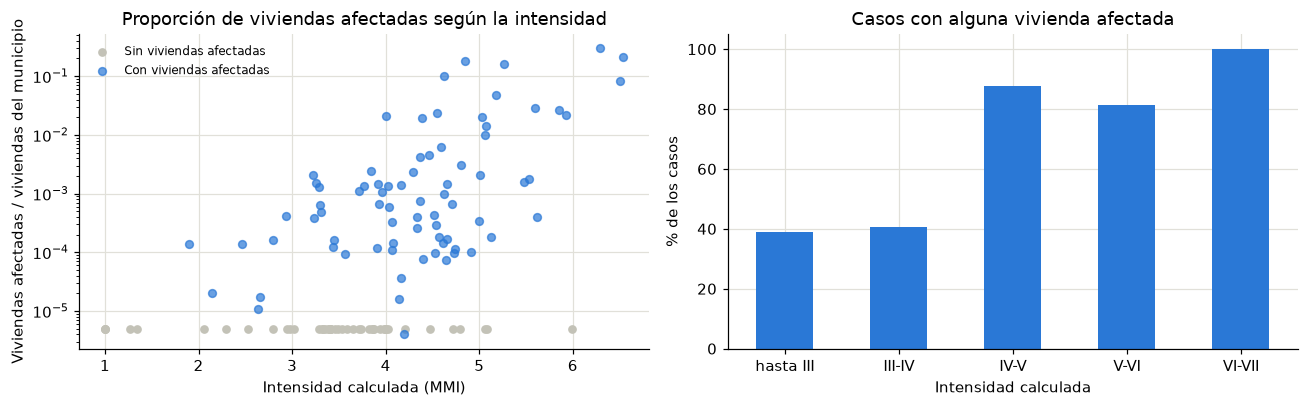

In [6]:
mayores = datos.groupby("sismo_id").agg(fecha=("fecha", "min"), magnitud=("magnitud", "first"), profundidad_km=("prof_km", "first"),
                                        municipios=("codigo_dane", "size"), viviendas_afectadas=("viviendas_afectadas", "sum")).sort_values("viviendas_afectadas", ascending=False)
print("Sismos con más viviendas afectadas:"); display(mayores.head(8))

fig, ejes = plt.subplots(1, 2, figsize=(12, 3.8))
con_dano = datos["viviendas_afectadas"] > 0
ejes[0].scatter(datos.loc[~con_dano, "intensidad_mmi"], np.full((~con_dano).sum(), 5e-6), color="#c3c2b7", s=22, label="Sin viviendas afectadas")
ejes[0].scatter(datos.loc[con_dano, "intensidad_mmi"], datos.loc[con_dano, "proporcion_afectada"], color=AZUL, s=26, alpha=0.7, label="Con viviendas afectadas")
ejes[0].set_yscale("log"); ejes[0].set(title="Proporción de viviendas afectadas según la intensidad", xlabel="Intensidad calculada (MMI)", ylabel="Viviendas afectadas / viviendas del municipio")
ejes[0].legend(frameon=False, fontsize=8)
tramos = pd.cut(datos["intensidad_mmi"], [0, 3, 4, 5, 6, 7], labels=["hasta III", "III-IV", "IV-V", "V-VI", "VI-VII"])
(100 * con_dano.groupby(tramos, observed=True).mean()).plot.bar(ax=ejes[1], color=AZUL, rot=0)
ejes[1].set(title="Casos con alguna vivienda afectada", xlabel="Intensidad calculada", ylabel="% de los casos"); plt.tight_layout(); plt.show()

**Qué se observa.**

- **Hay señal:** a más intensidad, más casos con daño y mayor proporción de viviendas afectadas.
- **Pocos casos fuertes:** casi no hay casos por encima de intensidad VI, de modo que para sismos muy fuertes la curva será una extrapolación.
- **La intensidad es calculada, no medida,** con el catálogo del USGS y un cálculo físico que no se ha validado fuera de Santander.
- **Solo aparecen los municipios que reportaron.** Los que no reportaron nada no están, lo que puede exagerar el daño a intensidades bajas.

## 5. Valores en pesos

Para el costo se usa lo que el Fondo Nacional de Gestión del Riesgo registró como apoyo en las emergencias que afectaron viviendas, de cualquier tipo.

Emergencias con apoyo registrado: 768 de 37,295 (2.1%)
   de ellas, con viviendas afectadas: 296  ·  por sismo: 2


,count,mean,std,min,25%,50%,75%,max
apoyo por vivienda afectada (COP),296.000,"348,249,474.884","2,562,411,078.018",2.000,"1,369,844.825","7,939,133.127","54,081,087.117","37,087,812,439.588"


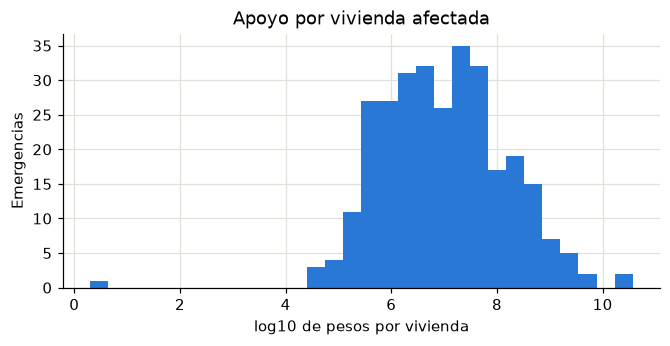

In [7]:
emergencias["viviendas_afectadas"] = emergencias["viviendas_averiadas"] + emergencias["viviendas_destruidas"]
con_apoyo = emergencias[(emergencias["apoyo_total_cop"] > 0) & (emergencias["viviendas_afectadas"] > 0)]
por_vivienda = con_apoyo["apoyo_total_cop"] / con_apoyo["viviendas_afectadas"]
print(f"Emergencias con apoyo registrado: {(emergencias['apoyo_total_cop'] > 0).sum():,} de {len(emergencias):,} ({(emergencias['apoyo_total_cop'] > 0).mean():.1%})")
print(f"   de ellas, con viviendas afectadas: {len(con_apoyo)}  ·  por sismo: {int(con_apoyo['evento'].str.contains('SISMO').sum())}")
display(por_vivienda.describe(percentiles=[0.25, 0.5, 0.75]).rename("apoyo por vivienda afectada (COP)").to_frame().T)
fig, eje = plt.subplots(figsize=(7, 3))
eje.hist(np.log10(por_vivienda), bins=30, color=AZUL); eje.set(title="Apoyo por vivienda afectada", xlabel="log10 de pesos por vivienda", ylabel="Emergencias"); plt.show()

**Qué se observa.** Muy pocas emergencias tienen valor registrado, casi ninguna es un sismo, y el valor por vivienda varía en varios órdenes
de magnitud. Por eso el costo se dará como **rango** (bajo, medio, alto), no como una cifra. Además, estos valores son lo que el Estado gastó
en atención (asistencia, materiales, subsidios de arriendo): no son el costo del daño ni una indemnización.

## 6. Entrenamiento y validación

El objetivo es la proporción de viviendas afectadas, que va de cero a una de cada cinco; por eso el modelo trabaja con su logaritmo.
Se comparan cuatro candidatos, y cada uno se valida **dejando fuera un sismo completo cada vez**: el modelo nunca ve el sismo que debe predecir.
Lo que sigue es la salida completa del script `entrenar_modelo_viviendas.py`.

In [8]:
import entrenar_modelo_viviendas as viviendas
import modelo_de_danos as md
viviendas.main()

MODELO DE VIVIENDAS AFECTADAS POR UN SISMO

1. Datos: 120 casos (municipio y sismo) de 27 sismos; 76 con viviendas afectadas
   -> Intensidad de 1.0 a 6.5; proporción afectada de 0 a 29.6%

2. Validación dejando fuera un sismo completo cada vez...



Candidato                                                           Error  Factor 10  Rangos  Viviendas
Referencia: siempre la mediana                                       1.29        38%   -0.21        287
Recta sobre el logaritmo de la proporción, según la intensidad       1.07        62%    0.53      1,173
Curva logística según la intensidad                                  1.56        43%    0.53     18,994
Random Forest con intensidad, magnitud, profundidad y distancia      1.24        61%    0.41      9,194
(viviendas afectadas reales)                                                                      3,818
   Error: error típico en órdenes de magnitud (0,5 = equivocarse por un factor 3). Menos es mejor.

   -> Modelo elegido: Recta sobre el logaritmo de la proporción, según la intensidad
      Reduce el error de la referencia en un 17%

3. Modelo final con todos los casos...
   -> Rango (del 25 % al 75 % de los casos): de x0.13 a x7.3 el valor central
   -> Viviendas destrui

,descripcion,error_tipico_log10,dentro_de_un_factor_10,correlacion_de_rangos,viviendas_predichas,viviendas_reales
constante,Referencia: siempre la mediana,1.292,0.383,-0.214,286.696,"3,818.000"
lineal,"Recta sobre el logaritmo de la proporción, seg...",1.069,0.625,0.526,"1,172.916","3,818.000"
logistica,Curva logística según la intensidad,1.559,0.433,0.526,"18,994.079","3,818.000"
bosque,"Random Forest con intensidad, magnitud, profun...",1.243,0.608,0.415,"9,194.320","3,818.000"


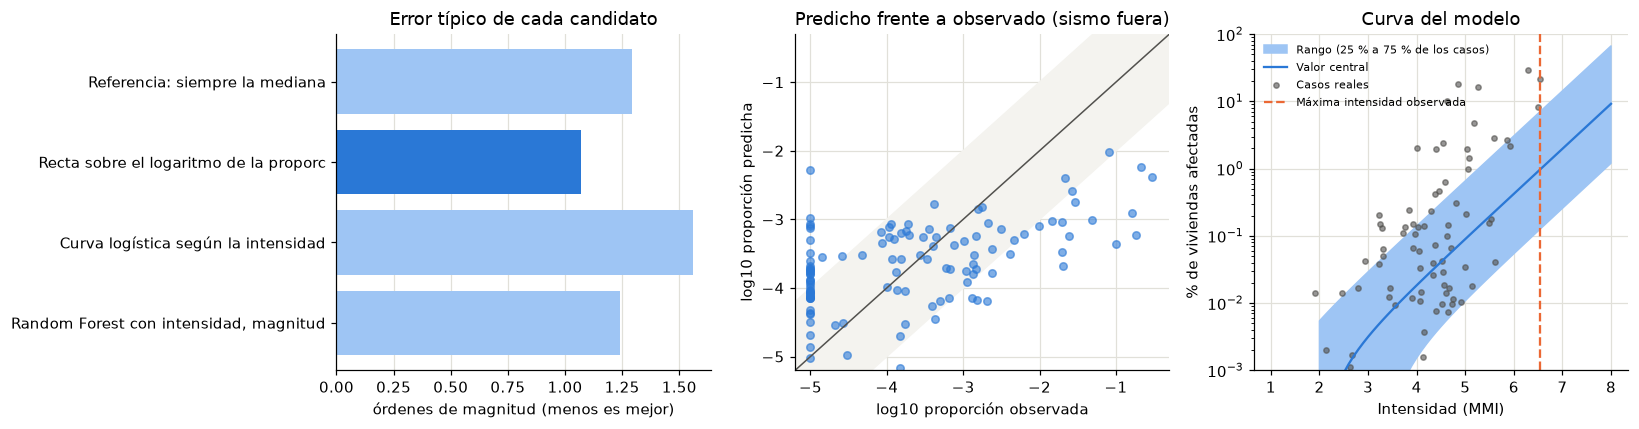

In [9]:
metricas = json.loads(viviendas.METRICAS_JSON.read_text(encoding="utf-8"))
candidatos = pd.DataFrame(metricas["candidatos"]).T
display(candidatos[["descripcion", "error_tipico_log10", "dentro_de_un_factor_10", "correlacion_de_rangos", "viviendas_predichas", "viviendas_reales"]])

modelo = viviendas.joblib.load(viviendas.MODELO_PKL)
caso = metricas["validacion_por_caso"]
observado, predicho, intensidad = np.array(caso["observado_log10"]), np.array(caso["predicho_log10"]), np.array(caso["intensidad_mmi"])
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
ejes[0].barh(candidatos["descripcion"].str.slice(0, 38), candidatos["error_tipico_log10"].astype(float),
             color=[AZUL if n == metricas["modelo_elegido"] else "#9ec5f4" for n in candidatos.index])
ejes[0].invert_yaxis(); ejes[0].set(title="Error típico de cada candidato", xlabel="órdenes de magnitud (menos es mejor)"); ejes[0].grid(axis="y", visible=False)
limites = (-5.2, -0.3)
ejes[1].fill_between(limites, [l - 1 for l in limites], [l + 1 for l in limites], color="#f4f3ef")
ejes[1].plot(limites, limites, color="#52514e", linewidth=1)
ejes[1].scatter(observado, predicho, color=AZUL, alpha=0.6, s=24)
ejes[1].set(title="Predicho frente a observado (sismo fuera)", xlabel="log10 proporción observada", ylabel="log10 proporción predicha", xlim=limites, ylim=limites)
x = np.linspace(2, 8, 61)
e = md.estimar(modelo, pd.DataFrame({"intensidad_mmi": x, "magnitud": 6.0, "prof_km": 30.0, "dist_epicentral_km": 30.0}), np.ones(len(x)))
ejes[2].fill_between(x, 100 * e["afectadas_bajo"], 100 * e["afectadas_alto"], color="#9ec5f4", label="Rango (25 % a 75 % de los casos)")
ejes[2].plot(x, 100 * e["afectadas"], color=AZUL, label="Valor central")
ejes[2].scatter(intensidad, 100 * md.de_log(observado), color="#52514e", s=12, alpha=0.6, label="Casos reales")
ejes[2].axvline(modelo["intensidad_validada"][1], color=NARANJA, linestyle="--", label="Máxima intensidad observada")
ejes[2].set_yscale("log"); ejes[2].set(title="Curva del modelo", xlabel="Intensidad (MMI)", ylabel="% de viviendas afectadas", ylim=(1e-3, 100)); ejes[2].legend(frameon=False, fontsize=7.5)
plt.tight_layout(); plt.show()

## 7. Qué tan bueno es este modelo

Hay que decirlo con claridad: **es un modelo de primera aproximación**.

- **Aprende algo real:** el modelo elegido reduce el error de la referencia sin aprendizaje y ordena bien los casos (más intensidad, más daño).
- **Pero su error es grande:** se equivoca típicamente en cerca de un orden de magnitud, es decir, puede dar diez veces más o diez veces menos viviendas que las reales.
  Por eso su resultado se presenta siempre como un **rango**, no como una cifra.
- **Por qué:** son 120 casos; la intensidad es calculada y no medida; los municipios que no reportaron no aparecen; y con la misma intensidad
  el daño real cambia mucho según cómo estén construidas las viviendas, dato que no tenemos.
- **Fuera de lo observado es extrapolación:** no hay casos por encima de intensidad 6,5.
- **El costo no es una indemnización:** es el gasto de atención del Estado por vivienda afectada, tomado de emergencias de todo tipo, porque casi ningún sismo registra valor.

**Uso recomendado:** como orden de magnitud para comparar escenarios («este sismo afectaría decenas de viviendas; aquel, miles»), no como pronóstico de daños.